In [1]:
import os, sys
ROOT = os.environ.get('DSP_DECONV_ROOT', os.getcwd())
for d in ['lib', 'data/raw', 'data/processed', 'results', 'figures', 'configs']:
    os.makedirs(f'{ROOT}/{d}', exist_ok=True)
if f'{ROOT}/lib' not in sys.path:
    sys.path.insert(0, f'{ROOT}/lib')
print(os.listdir(ROOT))

['03_experiments_new.ipynb', '.DS_Store', '04_real_data_new.ipynb', 'requirements.txt', '02_proposed_new.ipynb', 'README.md', 'results', '00_setup_data.ipynb', 'figures', 'configs', 'lib', '05_figures_new.ipynb', '01_forward_baselines_new.ipynb', '.git', 'data', 'Report.pdf']


In [2]:
import sys
import importlib

if "imp" not in sys.modules:
    sys.modules["imp"] = importlib

%load_ext autoreload
%autoreload 2

import numpy as np, scipy, skimage, matplotlib.pyplot as plt
print('numpy', np.__version__, '| scipy', scipy.__version__, '| skimage', skimage.__version__)

numpy 2.5.4 | scipy 1.18.1 | skimage 0.26.0


In [3]:
import yaml
CFG_PATH = f'{ROOT}/configs/params.yaml'
if not os.path.exists(CFG_PATH):
    cfg = dict(
        seeds=[0, 1, 2, 3, 4],
        psf_sigmas=[1.5, 2.5, 4.0],            
        gauss_noise=[0.005, 0.01, 0.02, 0.05], 
        poisson_peaks=[30, 100, 300],           
        crop=256,                               
        eps_band=1e-3,                          
    )
    yaml.safe_dump(cfg, open(CFG_PATH, 'w'))
cfg = yaml.safe_load(open(CFG_PATH))
cfg

{'crop': 256,
 'eps_band': 0.001,
 'gauss_noise': [0.005, 0.01, 0.02, 0.05],
 'poisson_peaks': [30, 100, 300],
 'psf_sigmas': [1.5, 2.5, 4.0],
 'seeds': [0, 1, 2, 3, 4]}

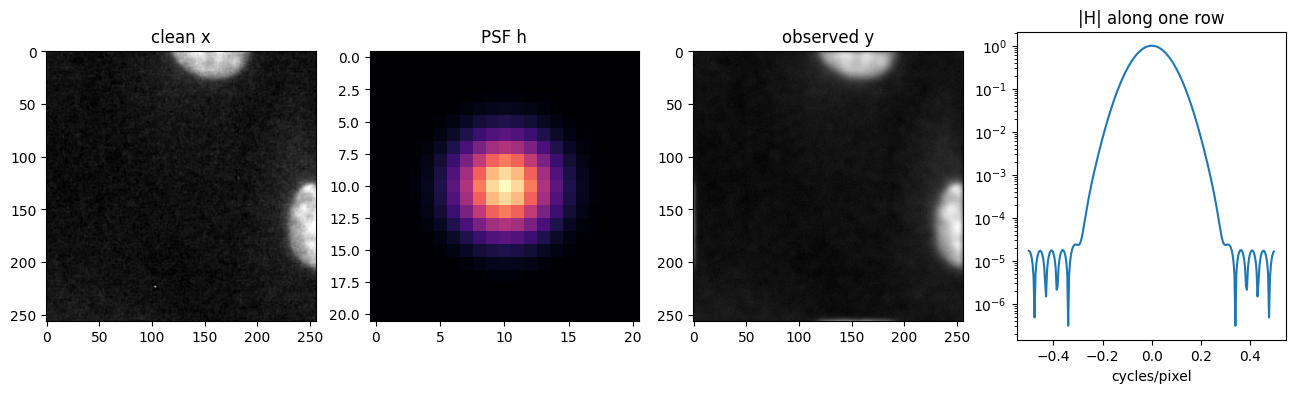

In [4]:
from forward import *; from data import *
gt, raw = fmd_pair('WideField_BPAE_B', 1)
x = center_crop(norm_pair(gt)[0], cfg['crop'])
psf = gaussian_psf(psf_size(2.5), 2.5)
y = add_gaussian(blur(x, psf), 0.01, np.random.default_rng(0))
H = np.fft.fftshift(np.abs(psf2otf(psf, x.shape)))
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].imshow(x, cmap='gray'); ax[0].set_title('clean x')
ax[1].imshow(psf, cmap='magma'); ax[1].set_title('PSF h')
ax[2].imshow(y, cmap='gray'); ax[2].set_title('observed y')
ax[3].semilogy(np.fft.fftshift(np.fft.fftfreq(256)), H[128]); ax[3].set_title('|H| along one row'); ax[3].set_xlabel('cycles/pixel')
plt.show()

In [5]:
from skimage import data as skd
from baselines import inverse
from forward import gaussian_psf, psf_size, blur, add_gaussian
import numpy as np

x = skd.camera()[:256, :256] / 255.0      
psf = gaussian_psf(psf_size(1.5), 1.5)
y0 = blur(x, psf)                                         
y1 = add_gaussian(y0, 0.001, np.random.default_rng(0))     
print('noiseless max error :', np.abs(inverse(y0, psf) - x).max())
print('tiny-noise max error:', np.abs(inverse(y1, psf) - x).max())

noiseless max error : 2.2536385424487548e-08
tiny-noise max error: 142091.1581826111


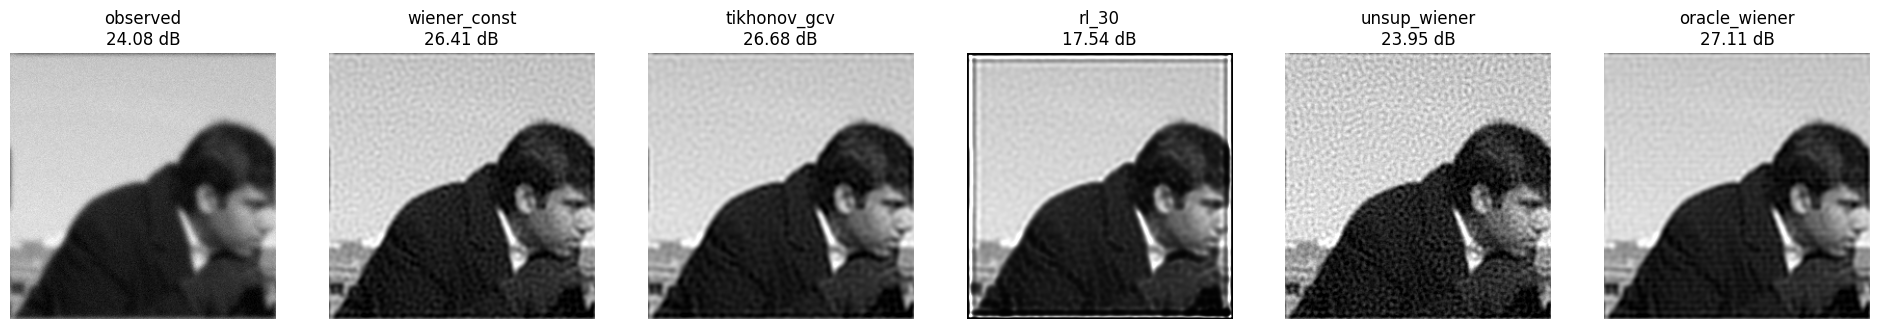

In [6]:
from metrics import psnr
from baselines import wiener_const, tikhonov_gcv, rl, unsup_wiener, wiener_oracle
psf = gaussian_psf(psf_size(2.5), 2.5); sigma = 0.02
y = add_gaussian(blur(x, psf), sigma, np.random.default_rng(0))
outs = {
    'observed':      y,
    'wiener_const':  wiener_const(y, psf, 1e-2),
    'tikhonov_gcv':  tikhonov_gcv(y, psf),
    'rl_30':         rl(y, psf, 30),
    'unsup_wiener':  unsup_wiener(y, psf),
    'oracle_wiener': wiener_oracle(y, psf, x, sigma),
}
fig, ax = plt.subplots(1, len(outs), figsize=(4 * len(outs), 4))
for a, (k, v) in zip(ax, outs.items()):
    a.imshow(np.clip(v, 0, 1), cmap='gray'); a.set_title(f'{k}\n{psnr(x, np.clip(v, 0, 1)):.2f} dB'); a.axis('off')

In [7]:
import yaml, numpy as np
from forward import *; from data import *; from baselines import *; from metrics import psnr

dev = []
for fov in [1, 2, 3]:                                   
    gt, _ = fmd_pair('WideField_BPAE_B', fov)
    dev.append(center_crop(norm_pair(gt)[0], cfg['crop']))

nsrs  = np.logspace(-4, 0, 17)
iters = [1, 2, 3, 4, 5, 7, 10, 20, 30, 50]
nsr_s = {n: [] for n in nsrs}
rl_s  = {k: [] for k in iters}

for xd in dev:
    for s_psf in cfg['psf_sigmas']:
        psf = gaussian_psf(psf_size(s_psf), s_psf)
        for s_n in cfg['gauss_noise']:
            y = add_gaussian(blur(xd, psf), s_n, np.random.default_rng(0))
            for n in nsrs:
                nsr_s[n].append(psnr(xd, np.clip(wiener_const(y, psf, n), 0, 1)))
            for k in iters:
                rl_s[k].append(psnr(xd, np.clip(rl(y, psf, k), 0, 1)))

mean_nsr = {n: np.mean(v) for n, v in nsr_s.items()}
mean_rl  = {k: np.mean(v) for k, v in rl_s.items()}
best_nsr  = float(max(mean_nsr, key=mean_nsr.get))
best_iter = int(max(mean_rl, key=mean_rl.get))
print('mean dev PSNR per RL iteration count:', {k: round(v, 2) for k, v in mean_rl.items()})
print('best nsr:', best_nsr, '| best rl_iter:', best_iter)
for name, best, grid in [('nsr', best_nsr, list(nsrs)), ('rl_iter', best_iter, iters)]:
    if best in (grid[0], grid[-1]):
        print(f'WARNING: best {name} = {best} is at the edge of its grid; widen the grid and re-run')

with open(f'{ROOT}/configs/tuned.yaml', 'w') as f:
    yaml.safe_dump(dict(nsr=best_nsr, rl_iter=best_iter), f)
print(open(f'{ROOT}/configs/tuned.yaml').read())

mean dev PSNR per RL iteration count: {1: np.float64(30.32), 2: np.float64(29.71), 3: np.float64(28.68), 4: np.float64(27.84), 5: np.float64(27.18), 7: np.float64(26.2), 10: np.float64(25.26), 20: np.float64(23.71), 30: np.float64(22.91), 50: np.float64(21.9)}
best nsr: 0.03162277660168379 | best rl_iter: 1
nsr: 0.03162277660168379
rl_iter: 1



In [8]:
from skimage.restoration import unsupervised_wiener
for s_psf, s_n in [(1.5, 0.01), (4.0, 0.05)]:
    psf = gaussian_psf(psf_size(s_psf), s_psf)
    y = add_gaussian(blur(dev[0], psf), s_n, np.random.default_rng(0))
    xh, chains = unsupervised_wiener(y, psf, clip=False, rng=0)
    sigma_est = 1 / np.sqrt(np.mean(chains['noise']))     
    print(f'PSF {s_psf} px, true sigma {s_n}: sampler sigma {sigma_est:.4f} | PSNR {psnr(dev[0], np.clip(xh, 0, 1)):.2f} dB')

PSF 1.5 px, true sigma 0.01: sampler sigma 0.0106 | PSNR 31.42 dB
PSF 4.0 px, true sigma 0.05: sampler sigma 0.0511 | PSNR 19.86 dB
